In [29]:
import polars as pl
fcs= pl.read_parquet("forecasts_price.parquet")
daa = pl.read_parquet("daa_price.parquet")
daa = daa.select(pl.col("delivery_start").dt.convert_time_zone("UTC"),pl.col("daa_price"))



In [30]:
result =(
    daa
    .join(fcs, on="delivery_start", how="full",coalesce=True)

) 
print(result)

shape: (23_424, 12)
┌───────────────┬───────────┬────────┬──────────┬───┬──────────┬──────────┬──────────┬─────────────┐
│ delivery_star ┆ daa_price ┆ entsoe ┆ enappsys ┆ … ┆ GFS_OP   ┆ EC_AIFS  ┆ EC_ENS   ┆ EC_AIFS_ENS │
│ t             ┆ ---       ┆ ---    ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---         │
│ ---           ┆ f64       ┆ f64    ┆ f64      ┆   ┆ f64      ┆ f64      ┆ f64      ┆ f64         │
│ datetime[μs,  ┆           ┆        ┆          ┆   ┆          ┆          ┆          ┆             │
│ UTC]          ┆           ┆        ┆          ┆   ┆          ┆          ┆          ┆             │
╞═══════════════╪═══════════╪════════╪══════════╪═══╪══════════╪══════════╪══════════╪═════════════╡
│ 2026-01-01    ┆ 60.01     ┆ 8469.0 ┆ 10310.0  ┆ … ┆ 45199.73 ┆ 45679.85 ┆ 46277.24 ┆ null        │
│ 00:00:00 UTC  ┆           ┆        ┆          ┆   ┆          ┆          ┆          ┆             │
│ 2026-01-01    ┆ 48.9      ┆ 7208.0 ┆ 9457.0   ┆ … ┆ 44941.64 ┆ 45670.

In [31]:
result.describe()

statistic,delivery_start,daa_price,entsoe,enappsys,energy_weather,EC_OP,EC_46,GFS_ENS,GFS_OP,EC_AIFS,EC_ENS,EC_AIFS_ENS
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""23424""",23328.0,15148.0,22605.0,17188.0,23424.0,23424.0,23424.0,23424.0,23424.0,23424.0,21888.0
"""null_count""","""0""",96.0,8276.0,819.0,6236.0,0.0,0.0,0.0,0.0,0.0,0.0,1536.0
"""mean""","""2026-05-02 23:52:30+00:00""",103.160362,27832.857869,27479.770936,28149.253829,52911.003723,52931.319474,52765.729521,52945.932811,52870.459851,52932.73848,52440.899011
"""std""",null,63.433959,15966.294137,18188.395467,18844.196712,8983.719882,8978.487376,9016.230691,9046.466562,9054.205683,8990.964845,8897.866845
"""min""","""2026-01-01 00:00:00+00:00""",-499.99,-12185.0,-37827.0,-42249.376398,34129.31,34250.02,34421.27,34650.83,34054.8,34354.65,34126.58
"""25%""","""2026-03-03 00:00:00+00:00""",80.0,16640.0,16489.0,16113.383102,45454.42,45442.45,45270.13,45420.31,45363.57,45460.75,45139.61
"""50%""","""2026-05-03 00:00:00+00:00""",109.71,30469.0,31077.0,32179.064898,53212.19,53253.26,53095.84,53205.12,53184.98,53217.13,52692.8
"""75%""","""2026-07-02 23:45:00+00:00""",138.39,39451.0,40201.0,42013.497308,58642.53,58741.14,58480.65,58751.92,58560.44,58697.94,58343.22
"""max""","""2026-09-01 23:45:00+00:00""",747.1,67181.0,74847.0,67764.264933,76412.3,75824.66,76264.85,76367.28,76793.11,76342.08,76504.72


In [32]:
# analyse BY USING MULTIPLE REGRESSION (residual load, weekend dummny, month dummny, hour dummy) => adjusted R2, MSE, MAE for all days and extreme prices day
# extract hour, weekday, month
df = result.with_columns(
    [
        pl.col("delivery_start").dt.hour().alias("hour"),
        pl.col("delivery_start").dt.weekday().alias("weekday"),
        pl.col("delivery_start").dt.month().alias("month")
    ]
)


# create weekend indicator
import pandas as pd
df = df.with_columns(
    (pl.col("weekday")>=5)
    .cast(pl.Int8)
    .alias("weekend")
)

pdf = df.to_pandas()

In [33]:
entsoe_clean = (
    pdf[
        ["delivery_start", "entsoe", "daa_price","weekend","hour","month"]
    ]
    .dropna()
)

In [34]:
print(entsoe_clean)

                 delivery_start   entsoe  daa_price  weekend  hour  month
0     2026-01-01 00:00:00+00:00   8469.0      60.01        0     0      1
1     2026-01-01 00:15:00+00:00   7208.0      48.90        0     0      1
2     2026-01-01 00:30:00+00:00   6298.0      36.74        0     0      1
3     2026-01-01 00:45:00+00:00   5804.0      23.93        0     0      1
4     2026-01-01 01:00:00+00:00   4976.0      36.01        0     1      1
...                         ...      ...        ...      ...   ...    ...
23219 2026-08-30 20:45:00+00:00  36294.0     175.34        1    20      8
23220 2026-08-30 21:00:00+00:00  35530.0     178.71        1    21      8
23221 2026-08-30 21:15:00+00:00  34967.0     167.37        1    21      8
23222 2026-08-30 21:30:00+00:00  34310.0     166.57        1    21      8
23223 2026-08-30 21:45:00+00:00  33593.0     162.50        1    21      8

[15148 rows x 6 columns]


In [35]:
#entsoe
import statsmodels.formula.api as smf

model = smf.ols(
    "daa_price ~ entsoe + weekend+ C(hour) + C(month)",
    data =entsoe_clean
).fit()


In [36]:
#extreme entsoe

q10 = entsoe_clean["daa_price"].quantile(0.10)
q90 = entsoe_clean["daa_price"].quantile(0.90)

print("Q10:", q10)
print("Q90:", q90)

extreme = entsoe_clean[
    (entsoe_clean["daa_price"] < q10) |
    (entsoe_clean["daa_price"] > q90)
].copy()

print(extreme)
print("Number of extreme observations:", len(extreme))


import statsmodels.formula.api as smf
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Multiple regression for extreme prices
model_extreme = smf.ols(
    "daa_price ~ entsoe + weekend + C(hour) + C(month)",
    data=extreme
).fit()

# Model summary
print(model_extreme.summary())


# Predictions
y_true = extreme["daa_price"]
y_pred = model_extreme.predict(extreme)


# Error metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

print("\nExtreme Price Performance")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
model_extreme.params["entsoe"]

Q10: 12.815000000000007
Q90: 170.35900000000004
                 delivery_start   entsoe  daa_price  weekend  hour  month
7     2026-01-01 01:45:00+00:00   2784.0       7.36        0     1      1
8     2026-01-01 02:00:00+00:00   1777.0      10.08        0     2      1
9     2026-01-01 02:15:00+00:00   1402.0       6.69        0     2      1
10    2026-01-01 02:30:00+00:00   1127.0       4.50        0     2      1
11    2026-01-01 02:45:00+00:00    646.0       3.87        0     2      1
...                         ...      ...        ...      ...   ...    ...
23216 2026-08-30 20:00:00+00:00  38106.0     189.32        1    20      8
23217 2026-08-30 20:15:00+00:00  37587.0     180.06        1    20      8
23218 2026-08-30 20:30:00+00:00  36871.0     181.03        1    20      8
23219 2026-08-30 20:45:00+00:00  36294.0     175.34        1    20      8
23220 2026-08-30 21:00:00+00:00  35530.0     178.71        1    21      8

[3030 rows x 6 columns]
Number of extreme observations: 3030
  

np.float64(0.004159769816143773)

In [37]:
# MSE; MAE of entsoe

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

pred = model.predict(entsoe_clean)
mae = mean_absolute_error(
    entsoe_clean["daa_price"],
    pred
)

mse = mean_squared_error(
    entsoe_clean["daa_price"],
    pred
)

rmse = np.sqrt(mse)

print("MAE:",mae)
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 19.500446218678857
MSE: 948.5736197046773
RMSE: 30.798922378951463


In [38]:
enappsys_clean = (
    pdf[
        ["delivery_start", "enappsys", "daa_price","weekend","hour","month"]
    ]
    .dropna()
)

In [39]:
model = smf.ols(
    "daa_price ~ enappsys + weekend+ C(hour) + C(month)",
    data =enappsys_clean
).fit()


In [40]:
pred = model.predict(enappsys_clean)
mae = mean_absolute_error(
    enappsys_clean["daa_price"],
    pred
)

mse = mean_squared_error(
    enappsys_clean["daa_price"],
    pred
)

rmse = np.sqrt(mse)

print("MAE:",mae)
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 19.790198951243205
MSE: 1006.8244647474356
RMSE: 31.73049739205857


In [41]:
#extreme enappysy

q10 = enappsys_clean["daa_price"].quantile(0.10)
q90 =enappsys_clean["daa_price"].quantile(0.90)

print("Q10:", q10)
print("Q90:", q90)

extreme = enappsys_clean[
    (enappsys_clean["daa_price"] < q10) |
    (enappsys_clean["daa_price"] > q90)
].copy()

print(extreme)
print("Number of extreme observations:", len(extreme))



import statsmodels.formula.api as smf
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Multiple regression for extreme prices
model_extreme = smf.ols(
    "daa_price ~ enappsys + weekend + C(hour) + C(month)",
    data=extreme
).fit()

# Model summary
print(model_extreme.summary())


# Predictions
y_true = extreme["daa_price"]
y_pred = model_extreme.predict(extreme)


# Error metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

print("\nExtreme Price Performance")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)

model_extreme.params["enappsys"]

Q10: 3.672000000000003
Q90: 165.92200000000005
                 delivery_start  enappsys  daa_price  weekend  hour  month
14    2026-01-01 03:30:00+00:00    3850.0       3.48        0     3      1
15    2026-01-01 03:45:00+00:00    3829.0       0.10        0     3      1
16    2026-01-01 04:00:00+00:00    3882.0       3.05        0     4      1
17    2026-01-01 04:15:00+00:00    2836.0       0.10        0     4      1
18    2026-01-01 04:30:00+00:00    2553.0       0.10        0     4      1
...                         ...       ...        ...      ...   ...    ...
23310 2026-08-31 19:30:00+00:00   22981.0     175.94        0    19      8
23312 2026-08-31 20:00:00+00:00   21133.0     176.20        0    20      8
23313 2026-08-31 20:15:00+00:00   20447.0     170.00        0    20      8
23314 2026-08-31 20:30:00+00:00   19709.0     172.94        0    20      8
23315 2026-08-31 20:45:00+00:00   18895.0     167.06        0    20      8

[4522 rows x 6 columns]
Number of extreme observatio

np.float64(0.003395550216470617)

In [42]:
# energy weather 
energy_weather_clean = (
    pdf[
        ["delivery_start", "energy_weather", "daa_price","weekend","hour","month"]
    ]
    .dropna()
)

In [43]:
model = smf.ols(
    "daa_price ~ energy_weather + weekend+ C(hour) + C(month)",
    data =energy_weather_clean
).fit()


In [44]:
pred = model.predict(energy_weather_clean)
mae = mean_absolute_error(
    energy_weather_clean["daa_price"],
    pred
)

mse = mean_squared_error(
    energy_weather_clean["daa_price"],
    pred
)

rmse = np.sqrt(mse)

print("MAE:",mae)
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 19.6145215072596
MSE: 998.7442636447793
RMSE: 31.602915429510286


In [45]:
#extreme energy weather

q10 = energy_weather_clean["daa_price"].quantile(0.10)
q90 = energy_weather_clean["daa_price"].quantile(0.90)

print("Q10:", q10)
print("Q90:", q90)

extreme = energy_weather_clean[
    (energy_weather_clean["daa_price"] < q10) |
    (energy_weather_clean["daa_price"] > q90)
].copy()





import statsmodels.formula.api as smf
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Multiple regression for extreme prices
model_extreme = smf.ols(
    "daa_price ~ energy_weather + weekend + C(hour) + C(month)",
    data=extreme
).fit()

# Model summary
print(model_extreme.summary())


# Predictions
y_true = extreme["daa_price"]
y_pred = model_extreme.predict(extreme)


# Error metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

print("\nExtreme Price Performance")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)

model_extreme.params["energy_weather"]

Q10: 0.03
Q90: 168.02300000000002
                            OLS Regression Results                            
Dep. Variable:              daa_price   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.834
Method:                 Least Squares   F-statistic:                     558.7
Date:                Thu, 24 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:58:42   Log-Likelihood:                -18351.
No. Observations:                3432   AIC:                         3.677e+04
Df Residuals:                    3400   BIC:                         3.696e+04
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept 

np.float64(0.002955439894178648)

In [46]:
#kpler
kpler_clean = (
    pdf[
        ["delivery_start", "EC_AIFS_ENS", "daa_price","weekend","hour","month"]
    ]
    .dropna()
)

In [47]:
model = smf.ols(
    "daa_price ~  EC_AIFS_ENS + weekend+ C(hour) + C(month)",
    data =kpler_clean
).fit()


In [48]:
pred = model.predict(kpler_clean)
mae = round(mean_absolute_error(
    kpler_clean["daa_price"],
    pred
),2)

mse = round(mean_squared_error(
    kpler_clean["daa_price"],
    pred
),2)

rmse = round(np.sqrt(mse),2)

print("MAE:",mae)
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 30.14
MSE: 1888.05
RMSE: 43.45


In [49]:
q10 = kpler_clean["daa_price"].quantile(0.10)
q90 = kpler_clean["daa_price"].quantile(0.90)

print("Q10:", q10)
print("Q90:", q90)

extreme = kpler_clean[
    (kpler_clean["daa_price"] < q10) |
    (kpler_clean["daa_price"] > q90)
].copy()




import statsmodels.formula.api as smf
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Multiple regression for extreme prices
model_extreme = smf.ols(
    "daa_price ~ EC_AIFS_ENS + weekend + C(hour) + C(month)",
    data=extreme
).fit()

# Model summary
print(model_extreme.summary())


# Predictions
y_true = extreme["daa_price"]
y_pred = model_extreme.predict(extreme)


# Error metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

print("\nExtreme Price Performance")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)

model_extreme.params["EC_AIFS_ENS"]

Q10: 0.4409999999999991
Q90: 166.10800000000003
                            OLS Regression Results                            
Dep. Variable:              daa_price   R-squared:                       0.784
Model:                            OLS   Adj. R-squared:                  0.782
Method:                 Least Squares   F-statistic:                     489.7
Date:                Thu, 24 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:58:42   Log-Likelihood:                -23801.
No. Observations:                4360   AIC:                         4.767e+04
Df Residuals:                    4327   BIC:                         4.788e+04
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

np.float64(0.005218869608581582)

In [50]:
#correlation between forecasts and daa_price
forecasts = result.columns[2:]

rows = []

for f in forecasts:
    corr = result.select(
        pl.corr(pl.col(f), pl.col("daa_price"))
    ).item()

    rows.append({
        "forecast": f,
        "corr_with_daa_price": round(corr, 3)
    })

corr_matrix = pl.DataFrame(rows).sort("corr_with_daa_price",descending= True)

print(corr_matrix)

shape: (10, 2)
┌────────────────┬─────────────────────┐
│ forecast       ┆ corr_with_daa_price │
│ ---            ┆ ---                 │
│ str            ┆ f64                 │
╞════════════════╪═════════════════════╡
│ energy_weather ┆ 0.833               │
│ enappsys       ┆ 0.735               │
│ entsoe         ┆ 0.723               │
│ GFS_ENS        ┆ 0.122               │
│ EC_46          ┆ 0.121               │
│ EC_OP          ┆ 0.119               │
│ EC_AIFS        ┆ 0.119               │
│ EC_ENS         ┆ 0.117               │
│ GFS_OP         ┆ 0.116               │
│ EC_AIFS_ENS    ┆ 0.104               │
└────────────────┴─────────────────────┘


In [51]:
import os
print(os.environ.get("MPLBACKEND"))

module://matplotlib_inline.backend_inline


In [52]:
forecasts = ["entsoe","enappsys","energy_weather","EC_AIFS_ENS"]

rows = []

for a in forecasts:
    row = {"forecast": a}

    for b in forecasts:
        row[b] = round(
            result.select(pl.corr(a, b)).item(),
            3
        )

    rows.append(row)

corr_matrix = pl.DataFrame(rows)

print(corr_matrix)

shape: (4, 5)
┌────────────────┬────────┬──────────┬────────────────┬─────────────┐
│ forecast       ┆ entsoe ┆ enappsys ┆ energy_weather ┆ EC_AIFS_ENS │
│ ---            ┆ ---    ┆ ---      ┆ ---            ┆ ---         │
│ str            ┆ f64    ┆ f64      ┆ f64            ┆ f64         │
╞════════════════╪════════╪══════════╪════════════════╪═════════════╡
│ entsoe         ┆ 1.0    ┆ 0.952    ┆ 0.931          ┆ 0.365       │
│ enappsys       ┆ 0.952  ┆ 1.0      ┆ 0.949          ┆ 0.264       │
│ energy_weather ┆ 0.931  ┆ 0.949    ┆ 1.0            ┆ 0.173       │
│ EC_AIFS_ENS    ┆ 0.365  ┆ 0.264    ┆ 0.173          ┆ 1.0         │
└────────────────┴────────┴──────────┴────────────────┴─────────────┘


In [53]:
# fit a model : Random Forest Feature Importance
#When used within an statistical model to predict DAA prices, which one has the highest feature importance?

from sklearn.ensemble import RandomForestRegressor
import numpy as np

features = result.columns[2:]

df = (
    result
    .select(features + ["daa_price"])
    .drop_nulls()
)

X = df.select(features).to_numpy()
y = df["daa_price"].to_numpy()

rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1,
)

rf.fit(X, y)

importance = pl.DataFrame({
    "forecast": features,
    "importance": rf.feature_importances_
}).sort("importance", descending=True)

print(importance)

shape: (10, 2)
┌────────────────┬────────────┐
│ forecast       ┆ importance │
│ ---            ┆ ---        │
│ str            ┆ f64        │
╞════════════════╪════════════╡
│ energy_weather ┆ 0.784047   │
│ entsoe         ┆ 0.058018   │
│ enappsys       ┆ 0.056014   │
│ EC_46          ┆ 0.026657   │
│ GFS_ENS        ┆ 0.016737   │
│ GFS_OP         ┆ 0.014583   │
│ EC_AIFS        ┆ 0.013174   │
│ EC_AIFS_ENS    ┆ 0.011439   │
│ EC_OP          ┆ 0.009771   │
│ EC_ENS         ┆ 0.009559   │
└────────────────┴────────────┘


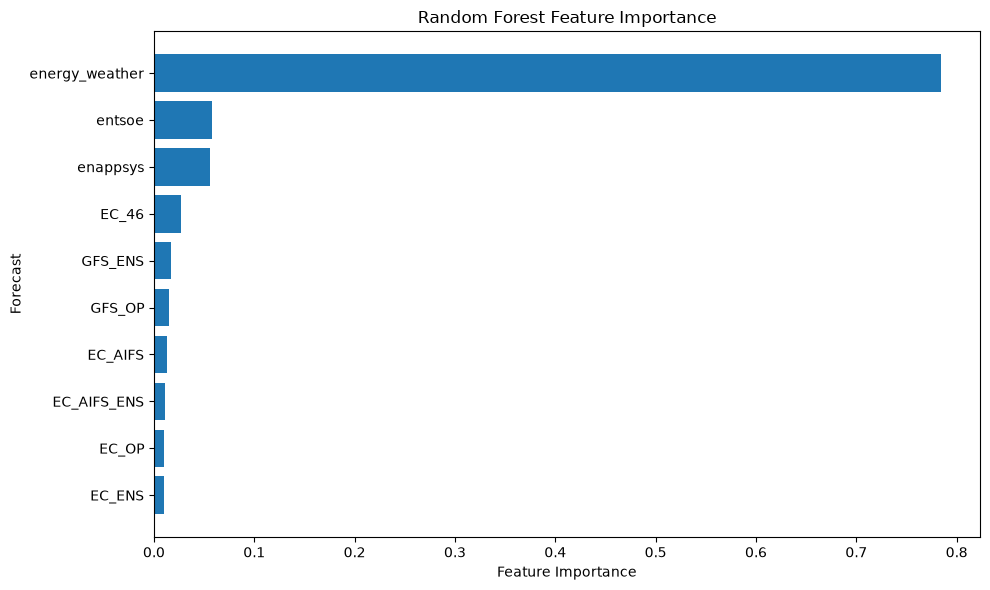

In [54]:
import matplotlib.pyplot as plt

# Convert Polars columns to NumPy
names = importance["forecast"].to_numpy()
values = importance["importance"].to_numpy()

plt.figure(figsize=(10, 6))

plt.barh(names, values)

# Put the most important feature at the top
plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Forecast")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [55]:
#4. which one ahs the highest predictive power for extreme DAA prices ( quantile 95)
forecast = result.columns[2:]


high_threshold = result.select(
    pl.col("daa_price").quantile(0.9)
).item()

low_threshold = result.select(pl.col("daa_price").quantile(0.1)).item()

extreme = result.filter((pl.col("daa_price")>= high_threshold) |
( pl.col("daa_price")<= low_threshold))
rows = []

for f in forecasts:
    rows.append({
        "forecast": f,
        "corr_extreme_daa": round(
            extreme.select(
                pl.corr(f, "daa_price")
            ).item(),
            3
        )
    })

extreme_corr = pl.DataFrame(rows).sort(
    "corr_extreme_daa",
    descending=True
)

print(extreme_corr)

shape: (4, 2)
┌────────────────┬──────────────────┐
│ forecast       ┆ corr_extreme_daa │
│ ---            ┆ ---              │
│ str            ┆ f64              │
╞════════════════╪══════════════════╡
│ energy_weather ┆ 0.893            │
│ entsoe         ┆ 0.886            │
│ enappsys       ┆ 0.865            │
│ EC_AIFS_ENS    ┆ 0.369            │
└────────────────┴──────────────────┘


In [56]:
print(extreme)

shape: (4_669, 12)
┌──────────────┬───────────┬─────────┬──────────┬───┬──────────┬──────────┬──────────┬─────────────┐
│ delivery_sta ┆ daa_price ┆ entsoe  ┆ enappsys ┆ … ┆ GFS_OP   ┆ EC_AIFS  ┆ EC_ENS   ┆ EC_AIFS_ENS │
│ rt           ┆ ---       ┆ ---     ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---         │
│ ---          ┆ f64       ┆ f64     ┆ f64      ┆   ┆ f64      ┆ f64      ┆ f64      ┆ f64         │
│ datetime[μs, ┆           ┆         ┆          ┆   ┆          ┆          ┆          ┆             │
│ UTC]         ┆           ┆         ┆          ┆   ┆          ┆          ┆          ┆             │
╞══════════════╪═══════════╪═════════╪══════════╪═══╪══════════╪══════════╪══════════╪═════════════╡
│ 2026-01-01   ┆ 0.1       ┆ 23.0    ┆ 3829.0   ┆ … ┆ 45012.95 ┆ 45194.22 ┆ 45298.44 ┆ null        │
│ 03:45:00 UTC ┆           ┆         ┆          ┆   ┆          ┆          ┆          ┆             │
│ 2026-01-01   ┆ 0.1       ┆ -445.0  ┆ 2836.0   ┆ … ┆ 44962.06 ┆ 45064.0